In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.datasets import load_diabetes

np.random.seed(42)
%matplotlib inline

      Hours      Score
0  4.370861  62.447527
1  9.556429  93.053829
2  7.587945  82.412305
3  6.387926  66.654868
4  2.404168  49.027153
            Hours       Score
count  100.000000  100.000000
mean     5.231627   67.431764
std      2.677405   16.453816
min      1.049699   40.045986
25%      2.738807   53.456196
50%      5.177282   65.521862
75%      7.571828   82.243492
max      9.881982   99.395583


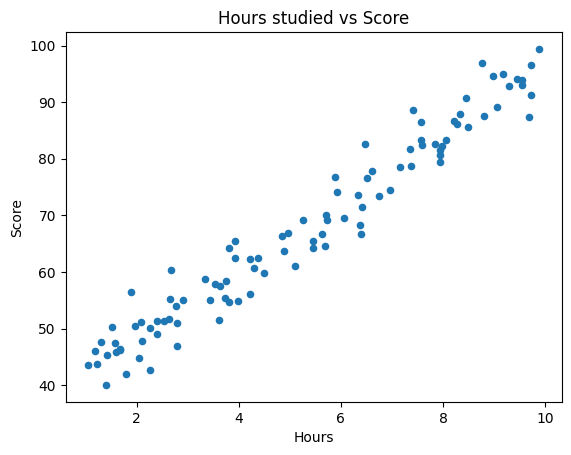

In [2]:
hours = np.random.uniform(1, 10, 100)
score = 35 + 6.2 * hours + np.random.normal(0, 4, 100)
df = pd.DataFrame({"Hours": hours, "Score": score})
print(df.head())
print(df.describe())

df.plot.scatter(x="Hours", y="Score", title="Hours studied vs Score")
plt.show()

In [3]:
X = df[["Hours"]]
y = df["Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept :", model.intercept_)
print("Slope     :", model.coef_[0])

y_pred = model.predict(X_test)
pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head()

Intercept : 36.325701662638394
Slope     : 5.961148043877174


,Actual,Predicted
0,50.970939,52.999414
1,86.546407,81.430464
2,82.412305,81.558568
3,92.914834,91.745709
4,83.264393,81.398327


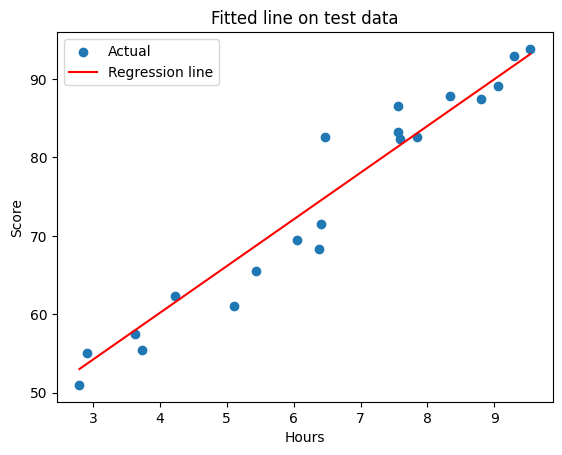

In [4]:
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test.sort_values("Hours"), model.predict(X_test.sort_values("Hours")), color="red", label="Regression line")
plt.xlabel("Hours"); plt.ylabel("Score"); plt.legend(); plt.title("Fitted line on test data")
plt.show()

In [5]:
mae  = metrics.mean_absolute_error(y_test, y_pred)
mse  = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = metrics.r2_score(y_test, y_pred)
print(f"MAE  : {mae:.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 2.558
MSE  : 10.721
RMSE : 3.274
R²   : 0.943


In [6]:
data = load_diabetes(as_frame=True)
dfd = data.frame
print(dfd.shape)
dfd.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [7]:
X = dfd.drop(columns="target")
y = dfd["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression().fit(X_train, y_train)
y_pred = mlr.predict(X_test)

coef = pd.DataFrame(mlr.coef_, index=X.columns, columns=["Coefficient"]).sort_values("Coefficient")
print("Intercept:", mlr.intercept_)
coef

Intercept: 151.34560453985995


,Coefficient
s1,-931.488846
sex,-241.964362
age,37.904021
s6,48.670657
s3,163.419983
s4,275.317902
bp,347.703844
s2,518.062277
bmi,542.428759
s5,736.198859


MAE  : 42.79
RMSE : 53.85
R²   : 0.453


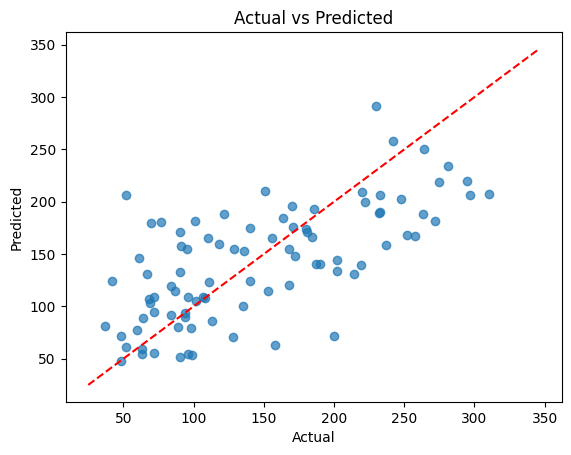

In [8]:
print(f"MAE  : {metrics.mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE : {np.sqrt(metrics.mean_squared_error(y_test, y_pred)):.2f}")
print(f"R²   : {metrics.r2_score(y_test, y_pred):.3f}")

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted")
plt.show()

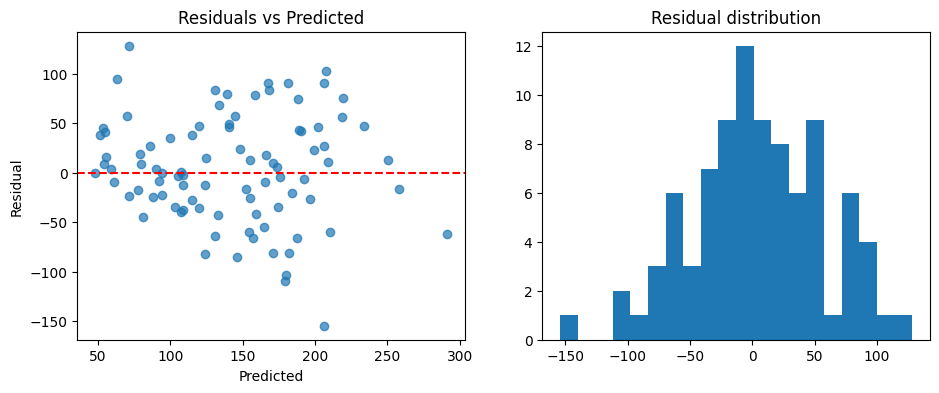

In [9]:
residuals = y_test - y_pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_pred, residuals, alpha=0.7); ax[0].axhline(0, color="r", ls="--")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title("Residuals vs Predicted")
ax[1].hist(residuals, bins=20); ax[1].set_title("Residual distribution")
plt.show()